# Decision Tree Regressor
Owner: Anupama Singh

Predicts the **gain** in points with a regression tree. The predicted gain is turned into a 0/1 label with the paper's rule so it can be compared with the classifiers.

## 1. Setup and data
Same data as the paper and as the rest of the team: 706 labeled students with no missing values, the paper's 16 features, two targets. The folds are identical to Megha's Random Forest and XGBoost notebooks.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
# Data: local copy in data/ if present, otherwise download from the ECRI repository
LOCAL = Path("../data")
URL = "https://raw.githubusercontent.com/ecri-data/ECRI-Dataset/main/ECRI"
src = LOCAL if (LOCAL / "ECRIDataSet.csv").exists() else URL

# Outputs: the repo's results/ folder when run locally, ./results in Colab
RESULTS = Path("../results") if Path("../results").exists() else Path("results")
RESULTS.mkdir(exist_ok=True)

# The paper's 16 features (Table 3) and the two Woodcock targets
FEATURES = ["Gender", "Tx", "Age1b", "Tier2_N", "grp_rate", "rcmistot", "gnrl_fid",
            "TKPctCrct", "NWFcls", "NWFwrc", "ORFwc", "SAwrS", "SAsrS", "SAtoS",
            "RMwidRS", "RMwdaRS"]
TARGETS = {"Word Identification": "RMwidRS", "Word Attack": "RMwdaRS"}

df = pd.read_csv(f"{src}/ECRIDataSet.csv")
raw = pd.read_csv(f"{src}/ECRIRawData.csv", low_memory=False)

# Spring scores are used ONLY to compute the gain (regression target), never as features
spring = raw[raw["Time"] == 2.0].set_index("StuID")[list(TARGETS.values())].add_suffix("_spring")

# Labeled students with no missing feature values, as in the paper (706 students)
data = (df[df["RMwidRS_target"].notna()]
        .dropna(subset=FEATURES)
        .join(spring, on="StuID")
        .reset_index(drop=True))
for score in TARGETS.values():
    data[f"{score}_gain"] = data[f"{score}_spring"] - data[score]

X = data[FEATURES]
print(f"Students: {len(data)} | Schools: {data['SchlID'].nunique()} | Features: {len(FEATURES)}")

Students: 706 | Schools: 42 | Features: 16


## 2. The model
- `max_depth` (2 to 8) is **tuned inside each training fold** with an inner 4-fold cross-validation, choosing the depth with the lowest mean absolute error. The test fold is never used for this choice.
- `min_samples_leaf=20`: every final group must hold at least 20 students.

Predicted label = 1 if the predicted gain is above the control group's average gain in the training folds.

In [2]:
MODEL_NAME = "Decision Tree Regressor"
KIND = "regressor"
DEPTHS = range(2, 9)


def build_model(depth):
    return DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=0)

def pick_depth(X_train, y_train, groups_train):
    """Inner 4-fold grouped CV on the training folds only; the test fold is never used."""
    scores = {d: cross_val_score(build_model(d), X_train, y_train, cv=GroupKFold(4),
                                 groups=groups_train, scoring="neg_mean_absolute_error").mean()
              for d in DEPTHS}
    return max(scores, key=scores.get)

## 3. 5-fold cross-validation
- **School split (main):** `GroupKFold(5)` on `SchlID`. Every school sits in exactly one test fold, so each student is scored by a model that never saw their school.
- **Student split:** `GroupKFold(5)` on `StuID`, so a school can appear in both training and test.

Each round trains on 4 folds (about 565 students) and predicts the 5th (about 141). The prediction for every student is saved so the evaluation notebook can compute all metrics and curves.

In [3]:
SPLITS = {"school": "SchlID", "student": "StuID"}


def cross_validate(score, split):
    """5-fold grouped cross-validation. Returns one row per student with the out-of-fold prediction."""
    groups = data[SPLITS[split]]
    y = data[f"{score}_target"] if KIND == "classifier" else data[f"{score}_gain"]
    rows = []
    for fold, (train_idx, test_idx) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), start=1):
        setting = pick_depth(X.iloc[train_idx], y.iloc[train_idx], groups.iloc[train_idx])
        model = build_model(setting).fit(X.iloc[train_idx], y.iloc[train_idx])
        test = data.iloc[test_idx]
        prediction = model.predict(test[FEATURES])                 # predicted gain in points
        # Turn the predicted gain into a label with the paper's rule:
        # 1 if above the training folds' control-group (Tx == 0) average gain
        train = data.iloc[train_idx]
        control_avg = train.loc[train["Tx"] == 0, f"{score}_gain"].mean()
        pred_label = (prediction > control_avg).astype(int)
        rows.append(pd.DataFrame({
            "split": split, "target": score, "model": MODEL_NAME, "fold": fold,
            "StuID": test["StuID"].values, "SchlID": test["SchlID"].values, "setting": setting,
            "true_label": test[f"{score}_target"].astype(int).values,
            "true_gain": test[f"{score}_gain"].values,
            "score": prediction,          # predicted gain in points
            "pred_label": pred_label,
        }))
    return pd.concat(rows, ignore_index=True)


predictions = pd.concat([cross_validate(score, split)
                         for split in SPLITS for score in TARGETS.values()], ignore_index=True)
print("Predictions:", len(predictions), "rows (706 students x 2 targets x 2 splits)")

Predictions: 2824 rows (706 students x 2 targets x 2 splits)


## 4. Quick summary
Mean over the 5 folds. The full set of metrics and curves (precision, recall, ROC and PR curves, squared error) is in `anupama_baseline_evaluation.ipynb`.

In [4]:
rows = []
for (split, score, fold), g in predictions.groupby(["split", "target", "fold"]):
    row = {"split": split, "target": score, "fold": fold,
           "ROC AUC": roc_auc_score(g["true_label"], g["score"]),
           "PR-AUC": average_precision_score(g["true_label"], g["score"]),
           "Accuracy": accuracy_score(g["true_label"], g["pred_label"])}
    row["MAE"] = mean_absolute_error(g["true_gain"], g["score"])
    rows.append(row)
fold_results = pd.DataFrame(rows)

summary = (fold_results.drop(columns="fold").groupby(["split", "target"])
           .agg(["mean", "std"]).round(3)
           .rename(index={v: k for k, v in TARGETS.items()}, level=1))
summary

ROC AUC        PR-AUC        Accuracy         \
                               mean    std   mean    std     mean    std   
split   target                                                             
school  Word Attack           0.554  0.036  0.619  0.063    0.585  0.034   
        Word Identification   0.647  0.036  0.641  0.052    0.646  0.030   
student Word Attack           0.594  0.037  0.651  0.032    0.609  0.026   
        Word Identification   0.646  0.034  0.631  0.066    0.662  0.047   

                               MAE         
                              mean    std  
split   target                             
school  Word Attack          5.986  0.158  
        Word Identification  6.701  0.431  
student Word Attack          5.865  0.659  
        Word Identification  6.718  0.153

## Tree depth chosen in each fold
Picked by the inner cross-validation inside each training fold.

In [5]:
(predictions.groupby(["split", "target", "fold"])["setting"].first()
 .unstack("fold").rename(index={v: k for k, v in TARGETS.items()}, level=1))

fold                         1  2  3  4  5
split   target                            
school  Word Attack          2  2  2  2  2
        Word Identification  2  3  4  3  2
student Word Attack          2  2  2  4  2
        Word Identification  2  2  2  2  2

## 6. Predicted vs actual gain (school split)
A tree predicts one value per final group, so predictions form horizontal bands.

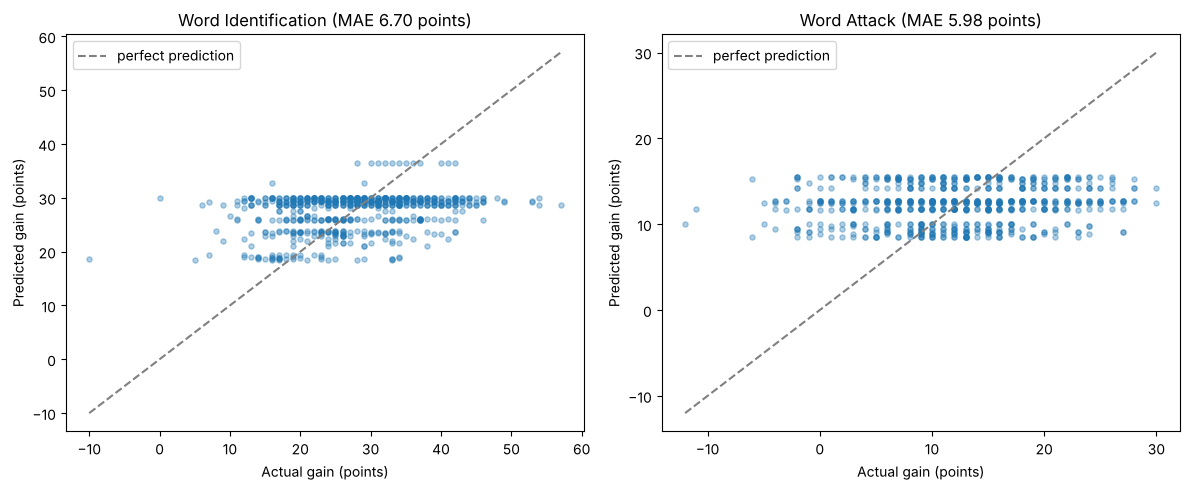

In [6]:
school = predictions[predictions["split"] == "school"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (target_name, score) in zip(axes, TARGETS.items()):
    p = school[school["target"] == score]
    ax.scatter(p["true_gain"], p["score"], alpha=0.35, s=14)
    lo, hi = p["true_gain"].min(), p["true_gain"].max()
    ax.plot([lo, hi], [lo, hi], linestyle="--", color="gray", label="perfect prediction")
    ax.set_title(f"{target_name} (MAE {mean_absolute_error(p['true_gain'], p['score']):.2f} points)")
    ax.set_xlabel("Actual gain (points)")
    ax.set_ylabel("Predicted gain (points)")
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "decision_tree_regressor_predicted_vs_actual.png", dpi=150)
plt.show()

## Save the results

In [7]:
predictions.to_csv(RESULTS / "decision_tree_regressor_cv_predictions.csv", index=False)
fold_results.to_csv(RESULTS / "decision_tree_regressor_cv_fold_results.csv", index=False)
print(f"Saved decision_tree_regressor_cv_predictions.csv and decision_tree_regressor_cv_fold_results.csv to {RESULTS}/")

Saved decision_tree_regressor_cv_predictions.csv and decision_tree_regressor_cv_fold_results.csv to ../results/
